# 6 Steps to build a Linear Regression model
Step 1: Importing the dataset
<p>Step 2: Data pre-processing</p>
<p>Step 3: Splitting the test and train sets</p>
<p>Step 4: Fitting the linear regression model to the training set</p>
<p>Step 5: Predicting test results</p>
<p>Step 6: Visualizing the test results</p>
<p>Step 7: Evaluate Model Performance </p>

In [2]:
#1. IMPORTING LIBRARIES & LOADING DATASET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from urllib.request import urlretrieve
from sklearn.model_selection import train_test_split

if not os.path.exists('housing.csv'):
    print('Downloading housing.csv...')
    urlretrieve(
        'https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv',
        'housing.csv'
    )
    print('Download complete.')


dataset = pd.read_csv('housing.csv')
dataset.head()
dataset  # Load the dataset and display the DataFrame for inspection

Download complete.


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [3]:
print('Dataset info:')
dataset.info()

print('\nMissing value counts:')
print(dataset.isna().sum())  # Inspect dataset schema, data types, and missing values

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing value counts:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median

In [4]:
dataset.info()  # Display dataset information again for confirmation

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [5]:
print('Statistical summary for the dataset:')
dataset.describe()  # Show summary statistics for numeric features and distribution

Statistical summary for the dataset:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [6]:
dataset.describe()  # Repeat the summary statistics for review

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [ ]:
# Placeholder cell: no additional code is required here.  # Maintain notebook structure with an explanatory comment

In [ ]:
#3. display the correlation heatmap and identify which attributes have strong and weak + correlation.
#Put your explanation in another text cell.

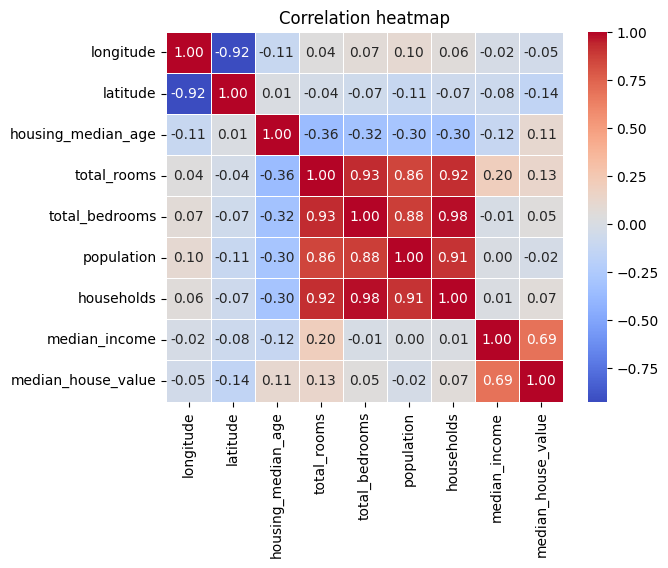

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation = dataset.drop('ocean_proximity', axis=1).corr()
sns.heatmap(correlation, annot = True, cmap = 'coolwarm', fmt=".2f", linewidths = 0.5)
plt.title('Correlation heatmap')
plt.show()  # Visualize the numeric feature correlations with a heatmap

In [8]:
#2. DATA PREPROCESSING
from sklearn.impute import SimpleImputer

#2.1 Define the target variable y-target (median_house_value)
y=dataset['median_house_value'].values


#2.2 Define the independent variables X
# Exclude 'median_house_value' (target) and 'ocean_proximity' (categorical) from X
X_numerical = dataset.drop(['median_house_value', 'ocean_proximity'], axis=1)

#2.3 Handle missing values in X_numerical using median imputation
imputer = SimpleImputer(strategy='median')
X = imputer.fit_transform(X_numerical)

# X is independent variable array and y is the dependent variable vector.
# Note the difference between the array and vector.
# The dependent variable must be in vector and independent variable must be an array itself.

print(X)  # Print the imputed feature array to confirm preprocessing output

[[-1.2223e+02  3.7880e+01  4.1000e+01 ...  3.2200e+02  1.2600e+02
   8.3252e+00]
 [-1.2222e+02  3.7860e+01  2.1000e+01 ...  2.4010e+03  1.1380e+03
   8.3014e+00]
 [-1.2224e+02  3.7850e+01  5.2000e+01 ...  4.9600e+02  1.7700e+02
   7.2574e+00]
 ...
 [-1.2122e+02  3.9430e+01  1.7000e+01 ...  1.0070e+03  4.3300e+02
   1.7000e+00]
 [-1.2132e+02  3.9430e+01  1.8000e+01 ...  7.4100e+02  3.4900e+02
   1.8672e+00]
 [-1.2124e+02  3.9370e+01  1.6000e+01 ...  1.3870e+03  5.3000e+02
   2.3886e+00]]


In [9]:
# Convert the NumPy array X back to a pandas DataFrame and verify for missing values
import pandas as pd

X_df = pd.DataFrame(X, columns = X_numerical.columns)
display(X_df.head())  # Show the first 5 rows after imputation to verify the feature table


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462


In [10]:
X_df.info()
X_df.describe()  # Verify the converted DataFrame has no missing values and view statistics

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20640 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,536.838857,1425.476744,499.539680,3.870671
std,2.003532,2.135952,12.585558,2181.615252,419.391878,1132.462122,382.329753,1.899822
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900
25%,-121.800000,33.930000,18.000000,1447.750000,297.000000,787.000000,280.000000,2.563400
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100


In [11]:
#DATE PREPROCESSING

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
rescaledX = scaler.fit_transform(X)

rescaledX  # Output the scaled features after MinMax scaling

array([[0.21115538, 0.5674814 , 0.78431373, ..., 0.00894083, 0.02055583,
        0.53966842],
       [0.21215139, 0.565356  , 0.39215686, ..., 0.0672104 , 0.18697583,
        0.53802706],
       [0.21015936, 0.5642933 , 1.        , ..., 0.01381765, 0.02894261,
        0.46602805],
       ...,
       [0.31175299, 0.73219979, 0.31372549, ..., 0.0281398 , 0.07104095,
        0.08276438],
       [0.30179283, 0.73219979, 0.33333333, ..., 0.02068444, 0.05722743,
        0.09429525],
       [0.30976096, 0.72582359, 0.29411765, ..., 0.03879032, 0.08699227,
        0.13025338]])

# 3. Splitting the dataset
We need to split our dataset into the test and train set. Generally, we follow the 20-80 policy or the 30-70 policy respectively.

Why is it necessary to perform splitting? This is because we wish to train our model according to the years and salary. We then test our model on the test set.

We check whether the predictions made by the model on the test set data matches what was given in the dataset.

If it matches, it implies that our model is accurate and is making the right predictions.

<p><b>random_state</b> is basically used for reproducing your problem the same every time it is run. If you do not use a random_state in train_test_split, every time you make the split you might get a different set of train and test data points</p>

<p><b>test_size</b> is the main configuration parameter of <b>train_test_split</b> , which is the size of the train and test sets.For example, a training set with the size of 0.67 (67 percent or 1/3) means that the remainder percentage 0.33 (33 percent) is assigned to the test set.</p>

In [12]:
#split the data using the normalized dataset = rescaledX

from sklearn.model_selection import train_test_split

X_train, X_test,y_train,y_test = train_test_split(rescaledX, y, test_size=.30, random_state = 0)



# 4. Fitting linear regression model into the training set
From sklearn’s linear model library, import linear regression class. Create an object for a linear regression class called regressor.

To fit the regressor into the training set, we will call the fit method – function to fit the regressor into the training set.

We need to fit X_train (training data of matrix of features) into the target values y_train. Thus the model learns the correlation and learns how to predict the dependent variables based on the independent variable.

In [13]:
from sklearn.linear_model import LinearRegression

regressor = LinearRegression()
regressor.fit(X_train, y_train)



LinearRegression()

In [14]:
#Print linear regression coefficient, y = b0 + b1x1

pd.DataFrame(regressor.coef_)

,0
0,-4.287725e+05
1,-3.982537e+05
2,5.912321e+04
3,-2.826164e+05
4,5.799619e+05
5,-1.305102e+06
6,3.839668e+05
7,5.852242e+05


# 5. Predicting the test set results
We create a vector containing all the predictions of the test set house values. The predicted house values are then put into the vector called y_pred.(contains prediction for all observations in the test set)

<b>predict</b> method makes the predictions for the test set. Hence, the input is the test set. The parameter for predict must be an array or sparse matrix, hence input is X_test.

<b>y_test</b> is the real salary of the test set.
<P><b>y_pred</b> are the predicted salaries.</P>

In [15]:
y_pred = regressor.predict(X_test)
y_pred

array([210982.23890681, 280019.81871801, 190640.9342763 , ...,
       366173.47229462,  94606.16902487, 268750.76922959])

# Visualizing the results

1. Plotting the points (observations)
To visualize the data, we plot graphs using matplotlib. To plot real observation points ie plotting the real given values.

The X-axis will have years of experience and the Y-axis will have the predicted salaries.

plt.scatter plots a scatter plot of the data. Parameters include :

X – coordinate (X_train: number of years)
Y – coordinate (y_train: real salaries of the employees)
Color ( Regression line in red and observation line in blue)
2. Plotting the regression line
plt.plot have the following parameters :

X coordinates (X_train) – number of years
Y coordinates (predict on X_train) – prediction of X-train (based on a number of years).
Note : The y-coordinate is not y_pred because y_pred is predicted salaries of the test set observations.

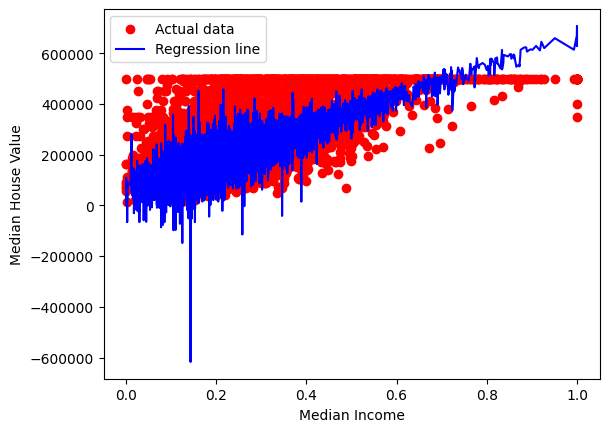

In [16]:
#plot for the TRAIN

# Select the 'median_income' feature for visualization (it's at index 7 in X_train)
X_train_median_income = X_train[:,7]

# Create an array of predictions for the training set
y_train_pred=regressor.predict(X_train)

# Create a DataFrame to sort both X_train_median_income and y_train_pred simultaneously for coherent plotting
import pandas as pd
plot_data=pd.DataFrame({'median_income':X_train_median_income,'predictions':y_train_pred})
plot_data_sorted = plot_data.sort_values(by='median_income')

plt.scatter(X_train_median_income, y_train,color='red', label='Actual data')

#Plot Regression line using sorted median_income with its prediction
plt.plot(plot_data_sorted['median_income'], plot_data_sorted['predictions'], color = 'blue', label='Regression line')
plt.xlabel('Median Income')
plt.ylabel('Median House Value')
plt.legend()
plt.show()


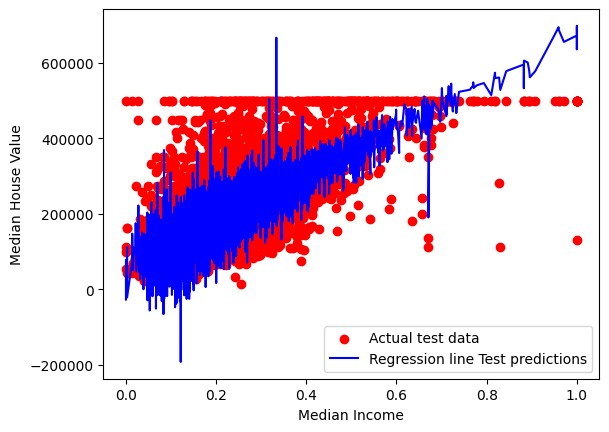

In [17]:
#plot for the TEST

# Select the 'median_income' feature for visualization (it's at index 7 in X_train)
X_test_median_income = X_test[:,7]

# Create an array of predictions for the training set
y_train_pred=regressor.predict(X_train)

# Create a DataFrame to sort both X_train_median_income and y_train_pred simultaneously for coherent plotting
import pandas as pd
plot_data_test=pd.DataFrame({'median_income':X_test_median_income,'predictions':y_pred})
plot_data_test_sorted = plot_data_test.sort_values(by='median_income')

plt.scatter(X_test_median_income, y_test,color='red', label='Actual test data')

#Plot Regression line using sorted median_income with its prediction
plt.plot(plot_data_test_sorted['median_income'], plot_data_test_sorted['predictions'], color = 'blue', label='Regression line Test predictions')
plt.xlabel('Median Income')
plt.ylabel('Median House Value')
plt.legend()
plt.show()

# Residuals
You should have gotten a very good model with a good fit. Let's quickly explore the residuals to make sure everything was okay with our data.

Plot a histogram of the residuals and make sure it looks normally distributed. Use either seaborn distplot, or just plt.hist().

In [18]:
#compute for residuals

y_pred2 = regressor.predict(rescaledX)
y_pred

array([210982.23890681, 280019.81871801, 190640.9342763 , ...,
       366173.47229462,  94606.16902487, 268750.76922959])

In [19]:
#visualize using dataframe

dataset['Predicted House Value']= y_pred2
dataset.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,Predicted House Value
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,412318.610062
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,419672.217216
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,381797.473378
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,322893.184188
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,254153.074780


In [20]:
#display actual median house value and the predicted to see residuals

actual_predicted = pd.DataFrame({"Actual_Median_House_Value":y_test, "Predicted House Value":y_pred})
display(actual_predicted)

,Actual_Median_House_Value,Predicted House Value
0,136900.0,210982.238907
1,241300.0,280019.818718
2,200700.0,190640.934276
3,72500.0,90501.686577
4,460000.0,294536.435018
...,...,...
6187,74000.0,126637.800092
6188,177300.0,162416.777789
6189,351900.0,366173.472295
6190,92500.0,94606.169025


In [21]:
#Evaluate Performance model using MEAN SQUARED ERROR, MEAN ABSOLUTE ERROR

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

print('MAE', mean_absolute_error(y_test, y_pred))
print('MSE', mean_squared_error(y_test, y_pred))
print('R2_SCORE', r2_score(y_test, y_pred))

#RESIDUAL = ACTUAL - PREDICTED





MAE 51015.24581094087
MSE 4953286829.509474
R2_SCORE 0.628476588515186


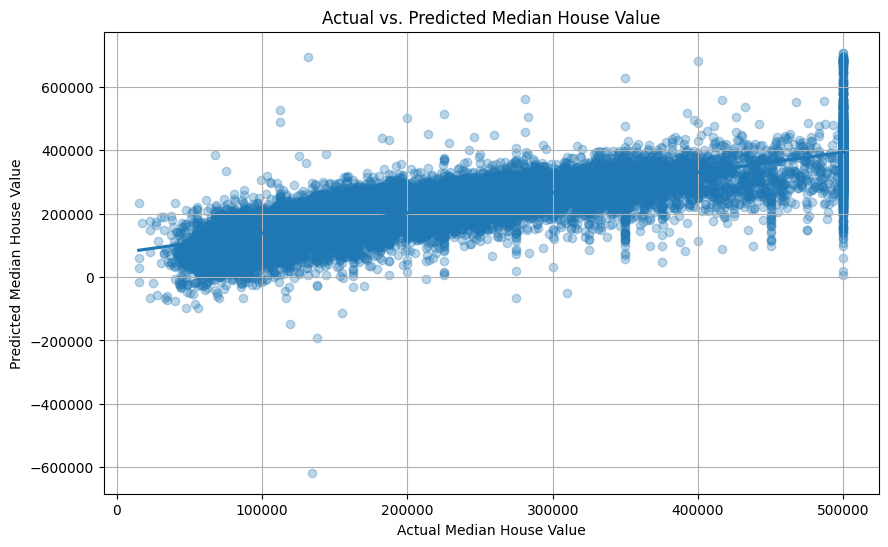

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.regplot(x='median_house_value', y='Predicted House Value', data=dataset, scatter_kws={'alpha':0.3})
plt.xlabel('Actual Median House Value')
plt.ylabel('Predicted Median House Value')
plt.title('Actual vs. Predicted Median House Value')
plt.grid(True)
plt.show()

In [ ]:
# Google Colab interactive sheets are not available in this environment.
# In Colab, use `from google.colab import sheets` and `sheets.InteractiveSheet(df=dataset)` to inspect the DataFrame.  # Explanation: disabled Colab-specific code for portability

In [23]:
actual_vs_predicted_df = dataset[['median_house_value', 'Predicted House Value']]
display(actual_vs_predicted_df.head())

,median_house_value,Predicted House Value
0,452600.0,412318.610062
1,358500.0,419672.217216
2,352100.0,381797.473378
3,341300.0,322893.184188
4,342200.0,254153.074780


/tmp/ipykernel_474/2910879304.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot((y_test), bins = 30)


<Axes: ylabel='Density'>

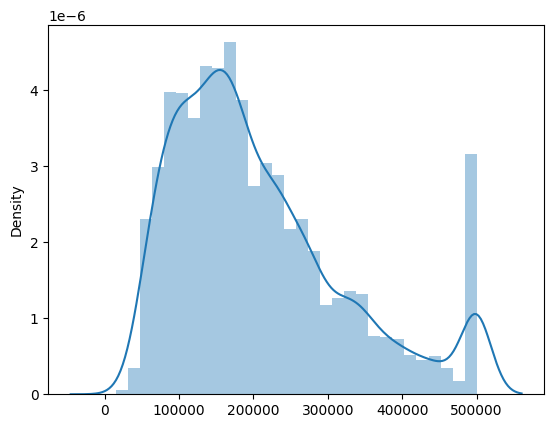

In [24]:
import seaborn as sns
sns.distplot((y_test), bins = 30)

In [25]:
from sklearn import metrics
from math import sqrt

print('MAE:',
      metrics.mean_absolute_error(y_test, y_pred), ' ',
      (1./len(y_test))*(sum(abs(y_test-y_pred))))
print('MSE:',
      metrics.mean_squared_error(y_test, y_pred), ' ',
      (1./len(y_test))*(sum((y_test-y_pred)**2)))
print('RMSE:',
      np.sqrt(metrics.mean_squared_error(y_test, y_pred)), ' ',
      sqrt((1./len(y_test))*(sum((y_test-y_pred)**2))))

MAE: 51015.24581094087   51015.245810940825
MSE: 4953286829.509474   4953286829.509468
RMSE: 70379.59100129436   70379.59100129432


In [26]:
#Measure the performance of the model
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
r2 = r2_score(y_test, y_pred) * 100
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(("r2: %.2f") %r2)
print(("mae: %.2f") %mae)
print(("mse: %.2f") %mse)
print(("rmse: %.2f") %rmse)

r2: 62.85
mae: 51015.25
mse: 4953286829.51
rmse: 70379.59


In [27]:
#YOUR TURN ACTIVITY
#DATA PREPROCESSING
# PERFORM DATA PREPROCESSING - STANDARD SCALER,BINARIZER.
# RUN THE SAME MODEL AND CHECK IF MSE, MAE, RMSE has changed


In [29]:
#predicting new value

regressor.fit(X.reshape(-1,1),y)
print('The predicted salary is:', regressor.predict([[20]]))

ValueError: Found input variables with inconsistent numbers of samples: [165120, 20640]

# Recursive feature elimination

The Recursive Feature Elimination (or RFE) works by recursively removing attributes and building a model on those attributes that remain.
It uses the model accuracy to identify which attributes (and combination of attributes) contribute the most to predicting the target attribute.

In [30]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
import pandas as pd

# Initialize RFE with the estimator and desired number of features to select
# Let's select 4 features for demonstration purposes. You can change this number.
# The original X_numerical has 8 columns, so 4 is a reasonable starting point.


# Fit RFE to the rescaled data (rescaledX) and target variable (y)


# Get the feature names from X_numerical for better interpretation

# Print the selected features
print("Selected Features:")
for i, selected in enumerate(rfe.support_):
    if selected:
        print(f"- {feature_names[i]}")

# Print the ranking of features (1 being the most important)
print("\nFeature Ranking:")
# Create a DataFrame to display feature names and their RFE ranks
rfe_ranking = pd.DataFrame({
    'Feature': feature_names,
    'Rank': rfe.ranking_
})
# Sort by rank for better readability
rfe_ranking = rfe_ranking.sort_values(by='Rank')
print(rfe_ranking)


Selected Features:


NameError: name 'rfe' is not defined

### Comparing Model Performance with RFE-selected Features

Now, let's train a new Linear Regression model using only the features selected by RFE and compare its performance to the original model (which used all numerical features).

In [31]:
#import helper libraries

# 1. Identify RFE-selected features
# Based on the previous RFE output, selected features have rank 1




# 2. Create a new dataset (X_rfe_df) with only these selected features


# 3. Rescale the new dataset using the same MinMaxScaler


# 4. Split the new dataset into training and testing sets (consistent with original split)


# 5. Train a new Linear Regression model on the RFE-selected features


# 6. Make predictions with the new model


# 7. Compare the results


# Principal component analysis

Principal Component Analysis (or PCA) uses linear algebra to transform the dataset into a compressed form.
Generally this is called a data reduction technique.
A property of PCA is that you can choose the number of dimensions or principal components in the transformed result.
As intuition:

It can be thought of as a projection method where data with m-columns (features) is projected into a subspace with m or fewer columns, whilst retaining the essence of the original data.
The PCA method can be described and implemented using the tools of linear algebra.
      

Where  A  is the original data that we wish to project,  BT  is the transpose of the chosen principal components and  P  is the projection of  A .
This is called the covariance method for calculating the PCA, although there are alternative ways to calculate it.
Also:

The eigenvectors represent the directions or components for the reduced subspace of  B , whereas the eigenvalues represent the magnitudes for the directions.
The eigenvectors can be sorted by the eigenvalues in descending order to provide a ranking of the components or axes of the new subspace for  A .

If all eigenvalues have a similar value, then we know that the existing representation may already be reasonably compressed or dense and that the projection may offer little.

If there are eigenvalues close to zero, they represent components or axes of  B  that may be discarded.

A total of  m  or less components must be selected to comprise the chosen subspace. Ideally, we would select k eigenvectors, called principal components, that have the  k  largest eigenvalues.

#Applying PCA in linear regression model

In [41]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn import metrics
import numpy as np
from sklearn.decomposition import PCA


print("### PCA-based Linear Regression Model ###\n")

# 1. Perform PCA on the rescaled data
# Choose 4 principal components, similar to the number of features selected by RFE
pca = PCA(n_components=4)
X_pca = pca.fit_transform(rescaledX)

print(f"Original of features: {rescaledX.shape[1]}")
print(f"PCA-transformed features: {X_pca.shape[1]}")


# 2. Split the PCA-transformed data into training and testing sets
# Keep the random_state consistent for reproducibility

X_train, X_test,y_train,y_test = train_test_split(X_pca, y, test_size = 0.30, random_state = 0)


# 3. Train a new Linear Regression model on the PCA components
regressor = LinearRegression()
regressor.fit(X_train, y_train)

# 4. Make predictions with the PCA model
y_pred = regressor.predict(X_test)
print(f'prediction: {y_pred}')



# 5. Evaluate the performance of the PCA model

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, root_mean_squared_error
import numpy as np

mse_pca = mean_squared_error(y_test, y_pred)
mae_pca = mean_absolute_error(y_test, y_pred)
r2_pca = r2_score(y_test, y_pred)
rmse_pca = root_mean_squared_error(y_test, y_pred)

print(f'Mean Squared Error: {mse}')
print(f'Mean Absolute Error: {mae}')
print(f'R-squared: {r2}')
print(f'Root Mean Squared Error: {rmse}')


# 6. Compare the results of all three models
comparison = {'Metric': ['MSE', 'MAE', 'RMSE', 'R-squared'], 'Original Model': [mse, mae, rmse, r2], 'RFE Model (4 Features)': ['N/A', 'N/A', 'N/A', 'N/A'], 'PCA Model (4 Features)': [mse_pca, mae_pca, rmse_pca, r2_pca]}
comparison_df = pd.DataFrame(comparison)
comparison_df


### PCA-based Linear Regression Model ###

Original of features: 8
PCA-transformed features: 4
prediction: [210846.05922083 297729.64664374 220128.19032492 ... 377623.32918875
 119540.06168708 245215.56755979]
Mean Squared Error: 6248757088.182264
Mean Absolute Error: 57974.5143927507
R-squared: 0.5313092839464554
Root Mean Squared Error: 79049.0802488066


,Metric,Original Model,RFE Model (4 Features),PCA Model (4 Features)
0,MSE,6.248757e+09,N/A,6.248757e+09
1,MAE,5.797451e+04,N/A,5.797451e+04
2,RMSE,7.904908e+04,N/A,7.904908e+04
3,R-squared,5.313093e-01,N/A,5.313093e-01
